# Deep Learning Final Project Team 2

## Description

## Data

In [35]:
from pathlib import Path

data_dir = Path("data/training")
# print("Working directory:", Path.cwd())
print("Files:", [p.name for p in data_dir.iterdir()])

Files: ['ENCFF357GNC.bigWig', 'ENCFF770EAV.bigWig', 'hg38.fa.gz', 'ENCFF667MDI.bigWig', 'ENCFF262URW.bigWig']


#### Look at the bigWig file

In [ ]:
import pyBigWig

with pyBigWig.open(f"{data_dir}/ENCFF667MDI.bigWig") as bw:
    print(f"Chromosome 1 length: {bw.chroms('chr1')}")
    print(f"First 10 values in the region: {bw.values('chr1', 1_000_000, 1_000_010)}")
    print(f'Number of chroms: {len(bw.chroms())}')
    for chrom in bw.chroms():
        print(f"Chromosome {chrom} length: {bw.chroms(chrom)}")

    print(f"bw.header(): {bw.header()}")

import gzip

with gzip.open(f"{data_dir}/hg38.fa.gz", "rt") as genome:
    print("First sequence header:", genome.readline().strip())
    print("First sequence line:", genome.readline().strip())


Chromosome 1 length: 248956422
First 10 values in the region: [32.249839782714844, 32.56003189086914, 31.58353042602539, 31.58353042602539, 31.57802963256836, 29.969650268554688, 31.57802963256836, 31.57802963256836, 32.147239685058594, 31.484899520874023]
Number of chroms: 160
Chromosome chr1 length: 248956422
Chromosome chr10 length: 133797422
Chromosome chr11 length: 135086622
Chromosome chr11_KI270721v1_random length: 100316
Chromosome chr12 length: 133275309
Chromosome chr13 length: 114364328
Chromosome chr14 length: 107043718
Chromosome chr14_GL000009v2_random length: 201709
Chromosome chr14_GL000194v1_random length: 191469
Chromosome chr14_GL000225v1_random length: 211173
Chromosome chr14_KI270722v1_random length: 194050
Chromosome chr14_KI270723v1_random length: 38115
Chromosome chr14_KI270724v1_random length: 39555
Chromosome chr14_KI270725v1_random length: 172810
Chromosome chr14_KI270726v1_random length: 43739
Chromosome chr15 length: 101991189
Chromosome chr15_KI270727v1_ra

#### Look at the reference genome (this can take a few minutes to run as the genome is large)

In [34]:
import gzip
import pandas as pd

records = []
current = None

with gzip.open(f"{data_dir}/hg38.fa.gz", "rt") as genome:
    for line in genome:
        if line.startswith(">"):
            if current is not None:
                records.append(current)

            current = {
                "sequence": line[1:].split()[0],
                "length": 0,
                "A": 0, "C": 0, "G": 0, "T": 0, "N": 0,
            }
        else:
            bases = line.strip().upper()
            current["length"] += len(bases)
            for base in "ACGTN":
                current[base] += bases.count(base)

if current is not None:
    records.append(current)

summary = pd.DataFrame(records)
known = summary["A"] + summary["C"] + summary["G"] + summary["T"]
summary["GC %"] = 100 * (summary["G"] + summary["C"]) / known.where(known > 0)

print(f"Sequences: {len(summary)}")
print(f"Total bases: {summary['length'].sum():,}")
display(summary.head(10))

Sequences: 455
Total bases: 3,209,286,105


,sequence,length,A,C,G,T,N,GC %
0,chr1,248956422,67070277,48055043,48111528,67244164,18475410,41.724292
1,chr10,133797422,38875926,27639505,27719976,39027555,534460,41.541536
2,chr11,135086622,39286730,27903257,27981801,39361954,552880,41.539808
3,chr11_KI270721v1_random,100316,18375,31042,31012,19887,0,61.858527
4,chr12,133275309,39370109,27092804,27182678,39492225,137493,40.766391
5,chr13,114364328,30047611,18839192,18933605,30162717,16381203,38.550309
6,chr14,107043718,26673415,18423758,18559033,26911943,16475569,40.834213
7,chr14_GL000009v2_random,201709,59480,39601,41195,61433,0,40.055724
8,chr14_GL000225v1_random,211173,56943,48931,51700,53599,0,47.653346
9,chr14_KI270722v1_random,194050,58529,38421,39525,57575,0,40.167998


### Explore the GM12878 signal

Plot a small region of chromosome 1 and select its highest signal position for a closer look.

length of the chromosome chr1: 248956422
len(plot_signal): 20000
['0.00001000', '0.00001000', '0.00001000', '0.00001000', '0.00001000', '0.00001000', '0.00001000', '0.00001000', '0.00001000', '0.00001000']


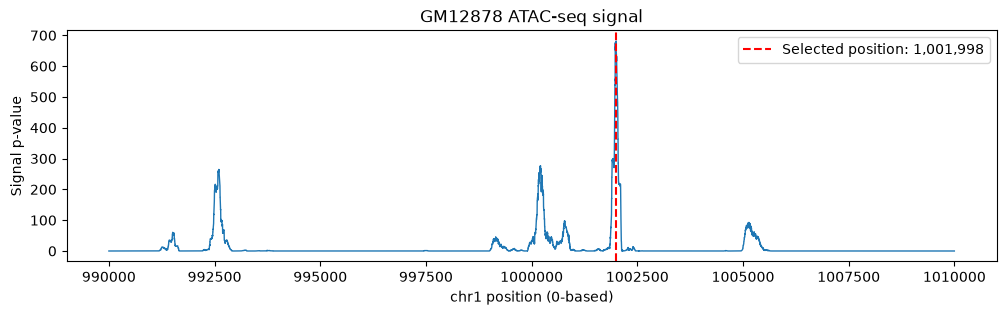

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

chrom = "chr1"
plot_start, plot_end = 990_000, 1_010_000
accession = "ENCFF667MDI"
accessions = ["ENCFF262URW", "ENCFF357GNC", "ENCFF667MDI", "ENCFF770EAV"]

with pyBigWig.open(f"{data_dir}/{accession}.bigWig") as bw:
    # help(bw.values)
    chrom_length = bw.chroms(chrom)
    print(f"length of the chromosome {chrom}: {chrom_length}")
    plot_signal = bw.values(chrom, plot_start, plot_end, numpy=True)
    print(f'len(plot_signal): {len(plot_signal)}')

print([f"{value:.8f}" for value in plot_signal[:10]])

# get the max peak in this region
peak_position = plot_start + int(np.argmax(np.where(np.isfinite(plot_signal), plot_signal, -np.inf)))
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(np.arange(plot_start, plot_end), plot_signal, linewidth=1)
ax.axvline(peak_position, color="red", linestyle="--", label=f"Selected position: {peak_position:,}")
ax.set(title="GM12878 ATAC-seq signal", xlabel=f"{chrom} position (0-based)", ylabel="Signal p-value")
ax.ticklabel_format(axis="x", style="plain", useOffset=False)
ax.legend()
plt.show()

### Align DNA sequence and signal

Match DNA and signal by genomic coordinates, rather than calculating a numerical correlation between them. The example uses 2,048 bases centered on the selected signal maximum. Following the paper, each target is the maximum of four consecutive signal values: 512 targets for training, with the central 256 corresponding to the central 1,024 bp used for evaluation. This is a single exploratory example, not a complete training dataset; blacklists, mappability filters, chromosome splits, and augmentation still need to be applied. Unknown DNA bases are encoded as all zeros, and missing signal remains NaN rather than being silently replaced.

peak_position: 1001998
window_start: 1000974, window_end: 1003022
len(sequence_parts): 42
fasta_length: 248956422, chrom_length: 248956422
Number of base pairs in sequence: 2048
one_hot shape: (2048, 4)
first few rows of one_hot:
[[0 1 0 0]
 [1 0 0 0]
 [0 0 1 0]
 [0 1 0 0]
 [1 0 0 0]]
Aligned window: chr1:1,000,974-1,003,022 (0-based, end-exclusive)
Chromosome lengths match: 248,956,422 bases
DNA input shape: (2048, 4); 4-bp target shape: (512,)
Ambiguous DNA bases: 0
Missing signal values: 0; bins containing missing values: 0


,start (0-based),DNA,max signal
0,1000974,CAGC,4.78149
1,1000978,AGCA,4.78588
2,1000982,AAGT,5.05120
3,1000986,GGGG,4.77447
4,1000990,CTCA,4.77447
5,1000994,CAGA,4.39493
6,1000998,AAAA,4.14519
7,1001002,TGAG,3.55169
8,1001006,GGGC,3.55169
9,1001010,CACT,3.54947


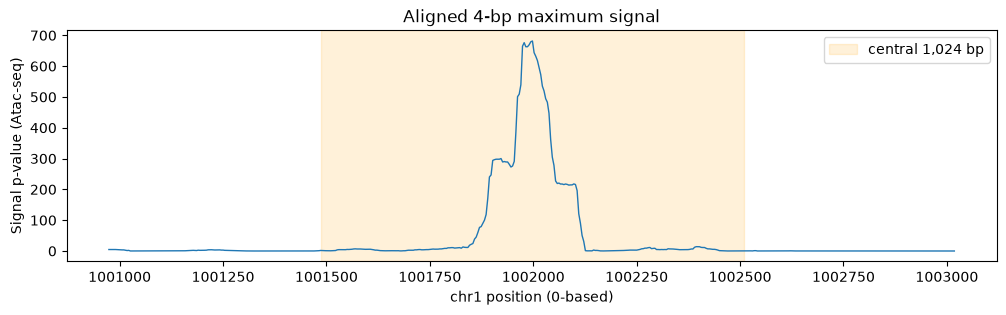

In [ ]:
import pandas as pd

reference_genome = "hg38"
chrom = "chr1"
accession = "ENCFF667MDI"
window_size = 2048
print(f"peak_position: {peak_position}")
window_start = peak_position - window_size // 2
window_end = window_start + window_size
print(f"window_start: {window_start}, window_end: {window_end}")

# Scan the compressed FASTA to extract the window and verify chromosome length.
sequence_parts = []
fasta_length = 0
found_chrom = False


with gzip.open(f"{data_dir}/{reference_genome}.fa.gz", "rt") as genome:
    for line in genome:
        if line.startswith(">"):
            # Stop after the we finish processing the chromosome listed above
            if found_chrom:
                break
            found_chrom = line[1:].split()[0] == chrom
            continue
        
        if found_chrom:
            bases = line.strip()
            line_end = fasta_length + len(bases)
            if fasta_length < window_end and line_end > window_start:
                sequence_parts.append(bases[max(0, window_start - fasta_length):min(len(bases), window_end - fasta_length)])
            fasta_length = line_end

print(f"len(sequence_parts): {len(sequence_parts)}")
print(f'fasta_length: {fasta_length}, chrom_length: {chrom_length}')
if fasta_length != chrom_length:
    raise ValueError(f"Chromosome length mismatch: FASTA={fasta_length}, bigWig={chrom_length}.")
sequence = "".join(sequence_parts).upper()
if len(sequence) != window_size:
    raise ValueError(f"Expected {window_size} bases, got {len(sequence)}.")

with pyBigWig.open(f"{data_dir}/{accession}.bigWig") as bw:
    signal = bw.values(chrom, window_start, window_end, numpy=True)

print(f"Number of base pairs in sequence: {len(sequence)}")

def one_hot_encode_base_pairs(sequence: list[str]) -> list[list[int]]:
    """sequence like ["A", "C", "G", "T"]
    Return example: [[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 1, 0], [0, 0, 0, 1]]
    """
    bases = np.array(list(sequence))
    possible_bases = np.array(["A", "G", "C", "T"])

    # return 1-D array into column to compare with possible_bases array
    one_hot = (bases[:, None] == possible_bases).astype(np.uint8)
    return one_hot

one_hot = one_hot_encode_base_pairs(sequence)

print(f"one_hot shape: {one_hot.shape}")
print(f"first few rows of one_hot:\n{one_hot[:5]}")
targets = signal.reshape(-1, 4).max(axis=1)
preview = pd.DataFrame({
    "start (0-based)": window_start + np.arange(512) * 4,
    "DNA": [sequence[i:i + 4] for i in range(0, window_size, 4)],
    "max signal": targets,
})

print(f"Aligned window: {chrom}:{window_start:,}-{window_end:,} (0-based, end-exclusive)")
print(f"Chromosome lengths match: {chrom_length:,} bases")
print(f"DNA input shape: {one_hot.shape}; 4-bp target shape: {targets.shape}")
print(f"Ambiguous DNA bases: {np.count_nonzero(one_hot.sum(axis=1) == 0)}") # Find any 'N' bases (missing)
print(f"Missing signal values: {np.isnan(signal).sum()}; bins containing missing values: {np.isnan(targets).sum()}")
display(preview.head(16))

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(preview["start (0-based)"], targets, linewidth=1)
ax.axvspan(window_start + 512, window_start + 1536, color="orange", alpha=0.15, label="central 1,024 bp")
ax.set(title="Aligned 4-bp maximum signal", xlabel=f"{chrom} position (0-based)", ylabel="Signal p-value (Atac-seq)")
ax.ticklabel_format(axis="x", style="plain", useOffset=False)
ax.legend()
plt.show()

## Pre-Processing

## Model

## Training

## Testing